# 07 — La transformada de Fourier cuántica

**Curso ECCI 2026 · Computación cuántica**

La QFT es la pieza que hace funcionar a QPE y a Shor. Y es un buen ejemplo de
algo
que suena más difícil de lo que es: **son $H$ y fases controladas, nada
más**.

Lo que hay que entender es qué le hace al estado:

> La QFT toma un número guardado en las **amplitudes** (la base
computacional)
> y lo reescribe en las **fases**, repartido entre los qubits como una
> expansión binaria.

Eso, dicho así, ya explica por qué aparece en QPE: si un algoritmo deja una
fase repartida entre qubits, la QFT **inversa** la junta y la convierte en
un
número que se puede medir.

Recorrido:

1. La definición, y la representación producto que da el circuito.
2. El circuito a mano: $H$, fases controladas y swaps, con la cuenta por
etapa.
3. **Las fases, vistas**: los discos por qubit muestran la expansión
binaria.
4. **El orden de los bits**: la trampa donde todo el mundo pierde una hora.
5. QFT ∘ IQFT = identidad, verificado.
6. La QFT de un estado periódico: el pico en la frecuencia (esto es Shor).
7. Escalado $n = 2 \ldots 7$ y la **QFT aproximada**.
8. Hardware real.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import (DensityMatrix, Operator, Statevector,
                                 partial_trace, state_fidelity)
from qiskit.visualization import plot_state_qsphere
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
SHOTS = 8192
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    qc.barrier(label=MARCAS[n - 1])
    return qc


print("listo")

listo


## Autenticación (opcional, y en memoria)

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. Qué es

La QFT es la transformada de Fourier discreta, aplicada a las **amplitudes**
de un estado. Sobre un estado de la base:

$$\mathrm{QFT}\,|x\rangle
 = \frac{1}{\sqrt N}\sum_{y=0}^{N-1} e^{2\pi i\,xy/N}\;|y\rangle,
 \qquad N = 2^n .$$

Y por linealidad, sobre cualquier estado $\sum_x \alpha_x|x\rangle$,
transforma
el vector de amplitudes exactamente como lo haría una DFT clásica.

### Por qué no es "exponencialmente más rápida" gratis

La FFT clásica necesita $O(N \log N) = O(2^n \, n)$ operaciones. La QFT
necesita $O(n^2)$ compuertas: **exponencialmente menos**. Pero hay una
trampa, y hay que decirla en voz alta: el resultado queda en las amplitudes
de un
estado cuántico, y **no se puede leer**. Medir devuelve un solo $y$, con
probabilidad $|\tilde\alpha_y|^2$.

Así que la QFT no sirve para "hacer Fourier rápido". Sirve cuando lo que
se quiere es **una propiedad global** del espectro —como un período, o una
fase— que se pueda extraer con pocas muestras. Eso es exactamente lo que
hacen Shor y QPE.

### La representación producto: de dónde sale el circuito

Acá está el corazón del asunto. La suma de arriba **factoriza**:

$$\mathrm{QFT}\,|x\rangle
 = \frac{1}{\sqrt{2^n}}
   \bigotimes_{k=1}^{n}\Big(|0\rangle + e^{2\pi
     i\,x/2^{k}}\,|1\rangle\Big).$$

Cada qubit queda en el **ecuador** de su esfera de Bloch —mitad y mitad— con
una fase que es $x$ dividido por una potencia de 2 distinta. El estado
resultante es **separable**: ningún entrelazamiento.

Leída al revés, la fórmula dice algo muy concreto: **cada qubit se lleva un
dígito binario de $x$**, en la fase. El qubit con $k = 1$ lleva $x/2$, o sea
el bit menos significativo; el de $k = n$ lleva $x/2^n$, la expansión
entera.
Cada qubit gira al doble de velocidad que el anterior.

---
# 2. El circuito

De la representación producto sale el circuito casi solo:

- una $H$ sobre el qubit $j$ pone la fase $x_j/2$ (el bit propio),
- cada fase controlada $CP(\pi/2^{d})$ agrega la contribución de un bit que
  está $d$ lugares más abajo,
- al final, **swaps** para arreglar el orden (§4).

¿coinciden con las de Qiskit?
  n=2:  QFT True   ·   IQFT True   ·   compuertas: 4  (n(n+1)/2 + swaps = 4)
  n=3:  QFT True   ·   IQFT True   ·   compuertas: 7  (n(n+1)/2 + swaps = 7)
  n=4:  QFT True   ·   IQFT True   ·   compuertas: 12  (n(n+1)/2 + swaps = 12)
  n=5:  QFT True   ·   IQFT True   ·   compuertas: 17  (n(n+1)/2 + swaps = 17)


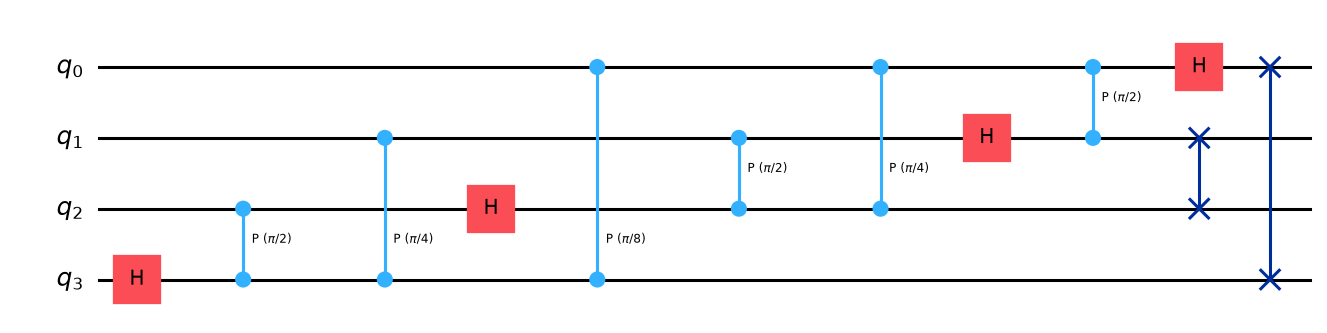

In [4]:
def qft(n: int, swaps: bool = True) -> QuantumCircuit:
    """QFT sobre n qubits, escrita a mano.

    Para cada qubit: H, y después las fases controladas por los qubits menos
    significativos, cada vez más chicas. Los swaps del final invierten el orden.
    """
    qc = QuantumCircuit(n, name="QFT")
    for j in reversed(range(n)):
        qc.h(j)
        for k in reversed(range(j)):
            qc.cp(np.pi / 2 ** (j - k), k, j)
    if swaps:
        for q in range(n // 2):
            qc.swap(q, n - 1 - q)
    return qc


def iqft(n: int, swaps: bool = True) -> QuantumCircuit:
    """La inversa: el mismo circuito al revés, con las fases negativas."""
    qc = QuantumCircuit(n, name="IQFT")
    if swaps:
        for q in range(n // 2):
            qc.swap(q, n - 1 - q)
    for j in range(n):
        for k in range(j):
            qc.cp(-np.pi / 2 ** (j - k), k, j)
        qc.h(j)
    return qc


print("¿coinciden con las de Qiskit?")
for n in (2, 3, 4, 5):
    a = QuantumCircuit(n); a.append(QFTGate(n), range(n))
    b = QuantumCircuit(n); b.append(QFTGate(n).inverse(), range(n))
    print(f"  n={n}:  QFT {Operator(qft(n)).equiv(Operator(a))}"
          f"   ·   IQFT {Operator(iqft(n)).equiv(Operator(b))}"
          f"   ·   compuertas: {len(qft(n).data)}  (n(n+1)/2 + swaps = "
          f"{n * (n + 1) // 2 + n // 2})")

display(qft(4).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa ($n = 3$, entrada $|101\rangle = |5\rangle$)

Tomamos $x = 5 = 101_2$, o sea $x_2 = 1$, $x_1 = 0$, $x_0 = 1$.

**①** $|\psi_1\rangle = |101\rangle$. El número está en las **amplitudes**:
una sola amplitud vale 1, las otras siete valen 0.

**②** Dado que se aplica $H$ al qubit 2 (el más significativo):
$$|\psi_2\rangle = \frac{|0\rangle + e^{2\pi i\,x_2/2}|1\rangle}{\sqrt2}
  \otimes |01\rangle .$$
La $H$ sobre $|1\rangle$ da $(|0\rangle - |1\rangle)/\sqrt2$, y ese signo
menos
es $e^{i\pi} = e^{2\pi i \cdot 1/2}$: la fase ya empezó a escribirse.

**③** Dado que se aplican las fases controladas $CP(\pi/2)$ y $CP(\pi/4)$
desde
los qubits 1 y 0 — que agregan $x_1/4$ y $x_0/8$ — el qubit 2 queda con la
fase completa
$$\frac{x_2}{2} + \frac{x_1}{4} + \frac{x_0}{8} = \frac{x}{8} = \frac{5}{8}.$$
**Ahí está la expansión binaria de $x/8$, sumada fase a fase.**

**④** Dado que se repite lo mismo para los qubits 1 y 0 (con menos términos
cada vez) y se aplican los swaps:
$$|\psi_4\rangle = \bigotimes_{k=1}^{3}
  \frac{|0\rangle + e^{2\pi i\,5/2^{k}}|1\rangle}{\sqrt2}.$$

El número salió de las amplitudes y quedó escrito en las fases.

---
# 3. Las fases, vistas

Acá los discos por qubit hacen exactamente lo que hay que ver: cada uno
queda
**medio lleno** (ecuador: $P(1) = 1/2$ en todos) y con la **aguja en un
ángulo
distinto**, que es la fase que le tocó.

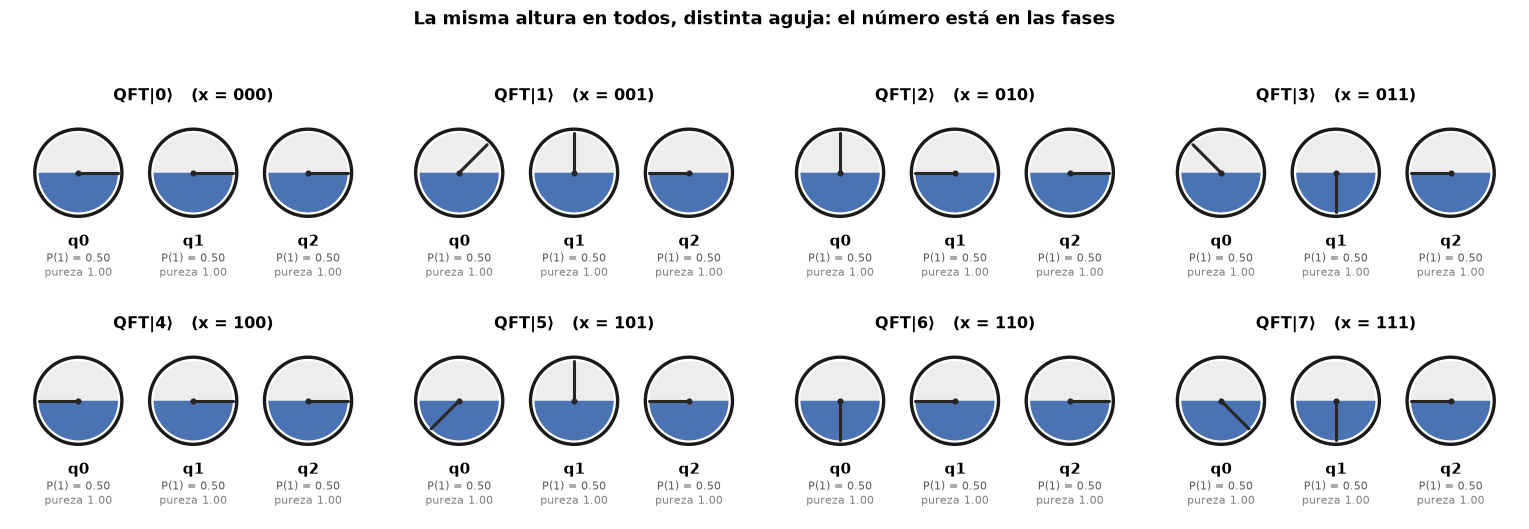

Fase relativa de cada qubit, en unidades de 2π:
 x |       q0       q1       q2  |  esperado x/2^(n-q)
 0 |    0.000    0.000    0.000  |  0.000 0.000 0.000
 1 |    0.125    0.250    0.500  |  0.125 0.250 0.500
 2 |    0.250    0.500    1.000  |  0.250 0.500 0.000
 3 |    0.375    0.750    0.500  |  0.375 0.750 0.500
 4 |    0.500    0.000    0.000  |  0.500 0.000 0.000
 5 |    0.625    0.250    0.500  |  0.625 0.250 0.500
 6 |    0.750    0.500    1.000  |  0.750 0.500 0.000
 7 |    0.875    0.750    0.500  |  0.875 0.750 0.500


In [5]:
def estado_base(n, x):
    qc = QuantumCircuit(n)
    for i, b in enumerate(format(x, f"0{n}b")[::-1]):
        if b == "1":
            qc.x(i)
    return qc


n_demo = 3
fig, ejes = plt.subplots(2, 4, figsize=(14, 5))
for ax, x in zip(ejes.ravel(), range(8)):
    qc = estado_base(n_demo, x)
    qc.compose(qft(n_demo), range(n_demo), inplace=True)
    utils.discos_qubits(Statevector(qc), ax=ax,
                        etiquetas=[f"q{q}" for q in range(n_demo)],
                        titulo=f"QFT|{x}⟩   (x = {format(x, '03b')})")
fig.suptitle("La misma altura en todos, distinta aguja: el número está en las fases",
             fontweight="bold", y=1.02)
utils.layout(fig)
plt.show()

print("Fase relativa de cada qubit, en unidades de 2π:")
print(f"{'x':>2} | " + " ".join(f"{'q' + str(q):>8}" for q in range(n_demo))
      + "  |  esperado x/2^(n-q)")
for x in range(8):
    qc = estado_base(n_demo, x)
    qc.compose(qft(n_demo), range(n_demo), inplace=True)
    rho = DensityMatrix(Statevector(qc))
    fases = []
    for q in range(n_demo):
        r = partial_trace(rho, [k for k in range(n_demo) if k != q]).data
        fases.append(np.angle(r[1, 0]) / (2 * np.pi) % 1)
    esperado = [x / 2 ** (n_demo - q) % 1 for q in range(n_demo)]
    print(f"{x:>2} | " + " ".join(f"{f:>8.3f}" for f in fases)
          + "  |  " + " ".join(f"{e:.3f}" for e in esperado))

La tabla confirma la representación producto: el qubit $q$ lleva la fase
$x/2^{\,n-q}$.

El patrón de las agujas al recorrer $x = 0, 1, \ldots, 7$ es regular: el
qubit 0
da media vuelta por cada unidad de $x$, el qubit 1 da un cuarto, el qubit 2
un
octavo. **Cada qubit gira al doble de velocidad que el anterior**, y el
número se lee mirando todas las agujas a la vez.

Esa es también la razón por la que la QFT es reversible y barata: no mezcla
qubits, solo reparte fases.

### La Q-sphere: el estado transformado

En la Q-sphere, `QFT|x⟩` se ve como los ocho estados básicos **todos del
mismo
tamaño** (porque todas las amplitudes tienen módulo $1/\sqrt8$) y con
**colores que giran** a ritmo proporcional a $x$. La frecuencia del giro
*es*
el número.

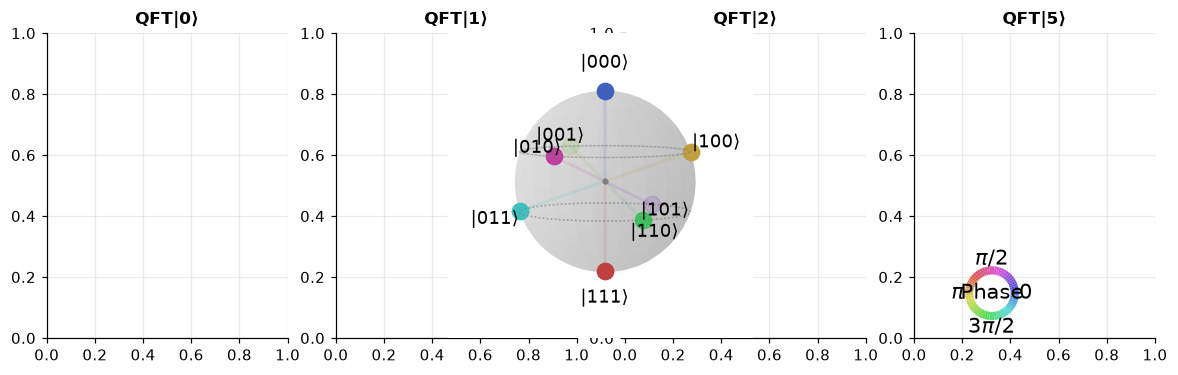

In [6]:
fig = plt.figure(figsize=(13, 3.6))
for i, x in enumerate([0, 1, 2, 5]):
    qc = estado_base(3, x)
    qc.compose(qft(3), range(3), inplace=True)
    ax = fig.add_subplot(1, 4, i + 1)
    plot_state_qsphere(Statevector(qc), ax=ax)
    ax.set_title(f"QFT|{x}⟩", fontsize=11)
plt.show()

---
# 4. El orden de los bits: la trampa

Acá es donde se pierde la hora, y es mejor perderla de una vez con el
ejemplo a la vista.

La representación producto entrega los qubits **en orden invertido**: el
factor que corresponde al bit más significativo sale en el qubit 0 y
viceversa. Por eso el circuito termina con $\lfloor n/2 \rfloor$ **swaps**.

Si te se olvida de los swaps, el circuito no está "mal": calcula la QFT con
los
bits al revés. Y como los resultados *parecen* razonables —los histogramas
tienen picos, las probabilidades suman 1— el error sobrevive mucho tiempo
sin ser detectado.

**La regla práctica: verificar siempre contra un caso que sepas de memoria.**
En QPE, el caso es $\varphi = 1/8$ con 3 qubits de conteo, que tiene que dar
`001`. Si da `100`, te faltaron los swaps.

In [7]:
n = 3
print("QFT sin swaps vs con swaps, aplicada a |x⟩ y midiendo después la IQFT completa:")
print(f"{'x':>2} {'con swaps':>12} {'sin swaps':>12}")
for x in range(8):
    fila = []
    for usar_swaps in (True, False):
        qc = estado_base(n, x)
        qc.compose(qft(n, swaps=usar_swaps), range(n), inplace=True)
        qc.compose(iqft(n, swaps=True), range(n), inplace=True)
        qc.add_register(ClassicalRegister(n, "c"))
        qc.measure(range(n), range(n))
        c = utils.correr_ideal(qc, shots=1024)
        fila.append(max(c, key=c.get))
    print(f"{x:>2} {fila[0]:>12} {fila[1]:>12}"
          + ("" if fila[1] == format(x, f'0{n}b') else "   ← bits invertidos"))

QFT sin swaps vs con swaps, aplicada a |x⟩ y midiendo después la IQFT completa:
 x    con swaps    sin swaps
 0          000          000


 1          001          100   ← bits invertidos
 2          010          110   ← bits invertidos


 3          011          011
 4          100          001   ← bits invertidos


 5          101          101
 6          110          010   ← bits invertidos


 7          111          100   ← bits invertidos


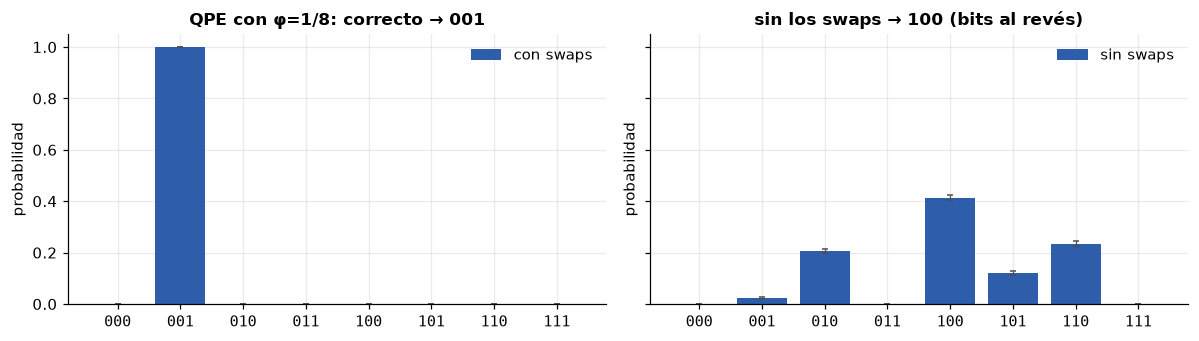

φ = 1/8 = 0.001₂ → el registro debe dar 001.
con swaps : 001
sin swaps : 100  ← 100₂ = 4, que sería φ = 1/2. Falso.


In [8]:
# Y el mismo error, visto en QPE: el caso de control que hay que conocer de memoria.
def qpe_demo(n_conteo, phi_frac, swaps=True):
    qc = QuantumCircuit(n_conteo + 1, n_conteo)
    qc.x(n_conteo)
    qc.h(range(n_conteo))
    for j in range(n_conteo):
        qc.cp(2 * np.pi * phi_frac * 2 ** j, j, n_conteo)
    qc.compose(iqft(n_conteo, swaps=swaps), range(n_conteo), inplace=True)
    qc.measure(range(n_conteo), range(n_conteo))
    return qc


c_ok = utils.correr_ideal(qpe_demo(3, 0.125, swaps=True), shots=2048)
c_mal = utils.correr_ideal(qpe_demo(3, 0.125, swaps=False), shots=2048)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
utils.comparar_conteos({"con swaps": c_ok}, claves=utils.claves_completas(3),
                       ax=ax1, titulo="QPE con φ=1/8: correcto → 001")
utils.comparar_conteos({"sin swaps": c_mal}, claves=utils.claves_completas(3),
                       ax=ax2, titulo="sin los swaps → 100 (bits al revés)")
utils.layout(fig)
plt.show()
print("φ = 1/8 = 0.001₂ → el registro debe dar 001.")
print("con swaps :", max(c_ok, key=c_ok.get))
print("sin swaps :", max(c_mal, key=c_mal.get), " ← 100₂ = 4, que sería φ = 1/2. Falso.")

---
# 5. QFT ∘ IQFT = identidad

Verificación obligatoria antes de confiar en cualquier implementación.

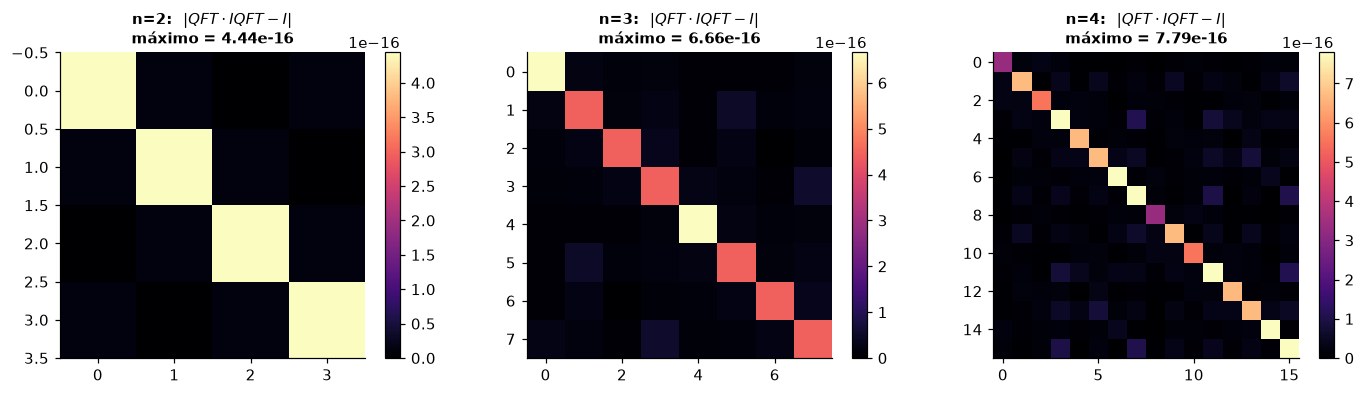

n=2: error máximo respecto de la identidad = 4.441e-16
n=3: error máximo respecto de la identidad = 6.661e-16
n=4: error máximo respecto de la identidad = 7.788e-16
n=5: error máximo respecto de la identidad = 8.948e-16
n=6: error máximo respecto de la identidad = 1.112e-15


In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, n in zip(ejes, (2, 3, 4)):
    U = Operator(qft(n)).data @ Operator(iqft(n)).data
    err = np.abs(U - np.eye(2 ** n))
    im = ax.imshow(err, cmap="magma", vmin=0, vmax=max(err.max(), 1e-16))
    ax.set_title(f"n={n}:  $|QFT \\cdot IQFT - I|$\nmáximo = {err.max():.2e}",
                 fontsize=10)
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046)
utils.layout(fig)
plt.show()

for n in (2, 3, 4, 5, 6):
    U = Operator(qft(n)).data @ Operator(iqft(n)).data
    print(f"n={n}: error máximo respecto de la identidad = "
          f"{np.abs(U - np.eye(2 ** n)).max():.3e}")

Cero hasta la precisión de máquina. La QFT es unitaria y la IQFT es su
adjunta, como tiene que ser.

---
# 6. La QFT de un estado periódico

Este es **el** uso de la QFT, el que aparece en Shor. Si el estado de
entrada
es periódico con período $r$,

$$|\psi\rangle \propto \sum_{j} |x_0 + jr\rangle,$$

su transformada se concentra en los múltiplos de $N/r$. Medir devuelve uno
de
esos múltiplos, y de ahí se despeja $r$.

Es exactamente lo que hace una transformada de Fourier clásica con una señal
periódica — picos en las armónicas — pero acá el estado periódico apareció
gratis, como resultado de evaluar una función en superposición.

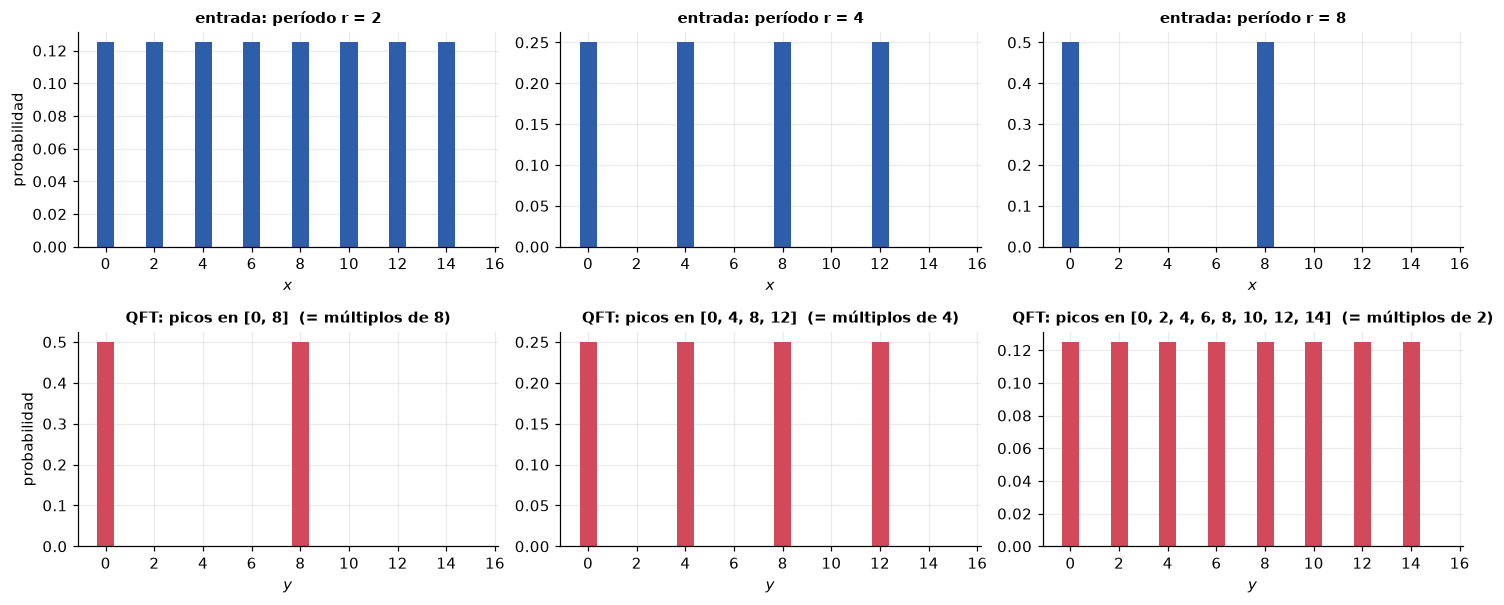

Regla: entrada de período r  →  salida concentrada en múltiplos de N/r.
Período grande en x  ⟺  picos juntos en y, y viceversa. Es la relación
de incerteza de Fourier de toda la vida.


In [10]:
n = 4
N = 2 ** n
fig, ejes = plt.subplots(2, 3, figsize=(13.5, 5.6))
for col, r in enumerate([2, 4, 8]):
    qc = QuantumCircuit(n)
    indices = list(range(0, N, r))
    amp = np.zeros(N, dtype=complex)
    amp[indices] = 1 / np.sqrt(len(indices))
    qc.initialize(amp, range(n))
    antes = np.abs(Statevector(qc).data) ** 2
    qc.compose(qft(n), range(n), inplace=True)
    despues = np.abs(Statevector(qc).data) ** 2

    ejes[0, col].bar(range(N), antes, color=utils.COLOR_IDEAL, width=0.7)
    ejes[0, col].set_title(f"entrada: período r = {r}", fontsize=10)
    ejes[0, col].set_xlabel("$x$")
    ejes[1, col].bar(range(N), despues, color=utils.COLOR_RUIDO, width=0.7)
    picos = [y for y in range(N) if despues[y] > 0.01]
    ejes[1, col].set_title(f"QFT: picos en {picos}  (= múltiplos de {N // r})",
                           fontsize=10)
    ejes[1, col].set_xlabel("$y$")
ejes[0, 0].set_ylabel("probabilidad")
ejes[1, 0].set_ylabel("probabilidad")
utils.layout(fig)
plt.show()

print("Regla: entrada de período r  →  salida concentrada en múltiplos de N/r.")
print("Período grande en x  ⟺  picos juntos en y, y viceversa. Es la relación")
print("de incerteza de Fourier de toda la vida.")

---
# 7. Escalado, y la QFT aproximada

La QFT de $n$ qubits usa $n(n+1)/2$ compuertas. El problema es **cuáles**:
las
fases controladas más chicas valen $\pi/2^{\,d}$ con $d$ grande, o sea
rotaciones minúsculas. Para $n = 10$, la más chica es $\pi/512 \approx
0.006$
rad.

Y acá viene la observación práctica de Coppersmith: **esas rotaciones son
más
chicas que el ruido del hardware**. Aplicarlas no agrega precisión, agrega
errores. La **QFT aproximada** (AQFT) simplemente las tira: se queda con las
fases hasta cierta distancia $m$ y descarta el resto.

El resultado es sorprendentemente bueno: con $m \approx \log_2 n$ el error
es
despreciable, y el circuito pasa de $O(n^2)$ a $O(n \log n)$ compuertas.

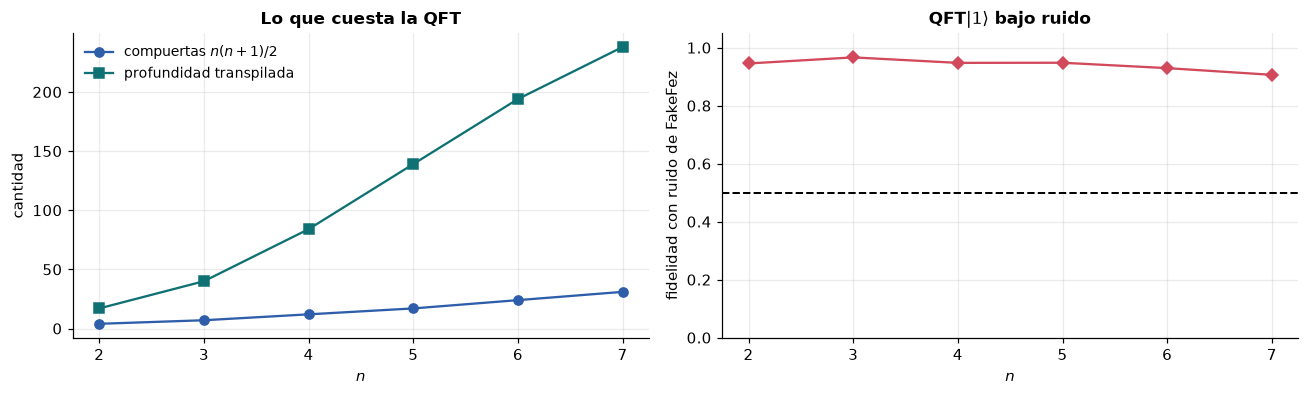

 n  compuertas  profundidad  fidelidad
 2           4           17     0.9455
 3           7           40     0.9665
 4          12           84     0.9476
 5          17          139     0.9480
 6          24          194     0.9294
 7          31          238     0.9063


In [11]:
def aqft(n: int, m: int) -> QuantumCircuit:
    """QFT aproximada: solo las fases controladas hasta distancia m."""
    qc = QuantumCircuit(n, name=f"AQFT(m={m})")
    for j in reversed(range(n)):
        qc.h(j)
        for k in reversed(range(j)):
            if j - k <= m:
                qc.cp(np.pi / 2 ** (j - k), k, j)
    for q in range(n // 2):
        qc.swap(q, n - 1 - q)
    return qc


NS = [2, 3, 4, 5, 6, 7]
compuertas, profundidades, fidelidades = [], [], []
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
pm_fez = generate_preset_pass_manager(optimization_level=1, backend=fez)
for n in NS:
    compuertas.append(len(qft(n).data))
    profundidades.append(pm_fez.run(qft(n)).depth())
    # fidelidad del estado QFT|1> bajo ruido, contra el ideal
    qc = estado_base(n, 1); qc.compose(qft(n), range(n), inplace=True)
    ideal = Statevector(qc)
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel
    nm = NoiseModel.from_backend(fez)
    from qiskit import transpile
    tq = transpile(qc, basis_gates=nm.basis_gates, optimization_level=1)
    tq.save_density_matrix(label="rho")
    rho = AerSimulator(method="density_matrix", noise_model=nm).run(
        tq, shots=1024).result().data(0)["rho"]
    fidelidades.append(state_fidelity(DensityMatrix(np.asarray(rho)),
                                      DensityMatrix(ideal)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.7))
ax1.plot(NS, compuertas, "o-", color=utils.COLOR_IDEAL, label="compuertas $n(n+1)/2$")
ax1.plot(NS, profundidades, "s-", color=utils.COLOR_HARD,
         label="profundidad transpilada")
ax1.set_xlabel("$n$"); ax1.set_ylabel("cantidad")
ax1.set_title("Lo que cuesta la QFT")
ax1.legend(fontsize=9)

ax2.plot(NS, fidelidades, "D-", color=utils.COLOR_RUIDO)
ax2.axhline(0.5, color="k", ls="--", lw=1.3)
ax2.set_xlabel("$n$"); ax2.set_ylabel("fidelidad con ruido de FakeFez")
ax2.set_ylim(0, 1.05)
ax2.set_title(r"QFT$|1\rangle$ bajo ruido")
utils.layout(fig)
plt.show()

print(f"{'n':>2} {'compuertas':>11} {'profundidad':>12} {'fidelidad':>10}")
for n, g, d, f in zip(NS, compuertas, profundidades, fidelidades):
    print(f"{n:>2} {g:>11} {d:>12} {f:>10.4f}")

In [12]:
# ¿Cuánto se pierde tirando las rotaciones chicas?
n = 6
print(f"QFT aproximada sobre {n} qubits:\n")
print(f"{'m':>3} {'compuertas':>11} {'fidelidad con la QFT exacta':>30}")
U_exacta = Operator(qft(n)).data
for m in range(1, n):
    U_aprox = Operator(aqft(n, m)).data
    # fidelidad promedio de proceso, vía |Tr(U†V)|²/d²
    f = abs(np.trace(U_exacta.conj().T @ U_aprox)) ** 2 / (2 ** n) ** 2
    print(f"{m:>3} {len(aqft(n, m).data):>11} {f:>30.6f}")
print(f"{'exacta':>3} {len(qft(n).data):>11} {1.0:>30.6f}")
print(f"\nlog2(n) = {np.log2(n):.2f}: con m=3 ya se recupera casi todo,")
print("y el circuito tiene la mitad de las compuertas.")

QFT aproximada sobre 6 qubits:

  m  compuertas    fidelidad con la QFT exacta
  1          14                       0.399872
  2          18                       0.856048
  3          21                       0.979141
  4          23                       0.998194
  5          24                       1.000000
exacta          24                       1.000000

log2(n) = 2.58: con m=3 ya se recupera casi todo,
y el circuito tiene la mitad de las compuertas.


**Con $m = 3$ sobre 6 qubits la fidelidad ya es prácticamente 1** y el
circuito tiene bastante menos compuertas. En hardware con ruido, la AQFT
muchas veces da **mejores** resultados que la exacta: las rotaciones que se
tiran aportaban menos señal que el error que introducían.

Es un ejemplo limpio de algo poco intuitivo: en NISQ, **un algoritmo
aproximado puede ser más preciso que el exacto**.

---
# 8. Hardware real

El test natural para la QFT en hardware es QFT seguida de IQFT sobre un
estado
de la base: idealmente devuelve el estado de partida, así que **cualquier
desvío es ruido puro**. Es un benchmark de fidelidad limpio, sin teoría de
por
medio.

In [13]:
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10}")
    print("-" * 46)
    for b in service.backends(simulator=False):
        st = b.status()
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  {st.status_msg:<10}")
else:
    print("sin autenticar")

sin autenticar


In [14]:
BACKEND_FIJO = None

backend = None
if service is not None:
    backend = (service.backend(BACKEND_FIJO) if BACKEND_FIJO
               else service.least_busy(operational=True, simulator=False))
    st = backend.status()
    print(f"elegido: {backend.name}  ·  {st.status_msg}  ·  cola {st.pending_jobs}")
else:
    print("sin autenticar: no hay backend")

sin autenticar: no hay backend


In [15]:
def ida_y_vuelta(n, x, aproximada=None):
    """QFT seguida de IQFT sobre |x>: tiene que devolver |x>."""
    qc = estado_base(n, x)
    marca(qc, 1)
    qc.compose(aqft(n, aproximada) if aproximada else qft(n), range(n), inplace=True)
    marca(qc, 2)
    qc.compose(iqft(n), range(n), inplace=True)
    marca(qc, 3)
    qc.add_register(ClassicalRegister(n, "c"))
    qc.measure(range(n), range(n))
    return qc


SHOTS_HW = 4096
CASOS_HW = ([(f"n3_x{x}", ida_y_vuelta(3, x)) for x in (1, 5)] +
            [(f"n4_x{x}", ida_y_vuelta(4, x)) for x in (1, 9)] +
            [("n5_x5", ida_y_vuelta(5, 5)),
             ("n5_x5_aqft2", ida_y_vuelta(5, 5, aproximada=2)),
             ("qpe_phi_1_8", qpe_demo(3, 0.125)),
             ("qpe_phi_1_8_sin_swaps", qpe_demo(3, 0.125, swaps=False))])

t_qft = None
if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    t_qft = pm.run([c for _, c in CASOS_HW])
    print("=== QFT: ida y vuelta + AQFT + control de swaps ===")
    costo = utils.informe_transpilacion(t_qft, shots=SHOTS_HW,
                                        nombre_backend=backend.name)
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


In [16]:
ENVIAR_QFT = False    # ponerlo en True para gastar QPU

if ENVIAR_QFT:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_qft, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"07 QFT: ida y vuelta n=3,4,5 + AQFT + swaps, {SHOTS_HW} shots",
                        notebook="07", experimento="qft",
                        n_circuitos=len(t_qft), shots=SHOTS_HW,
                        orden=[n for n, _ in CASOS_HW])
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


In [17]:
registros = utils.listar_jobs(filtro="07 ")

In [18]:
JOB_ID = ""   # vacío = el último job de QFT

if not JOB_ID:
    reg = utils.ultimo_job(experimento="qft")
    JOB_ID = reg["job_id"] if reg else ""
    if reg:
        print(f"último: {JOB_ID}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID and service is not None:
    res = utils.recuperar(service, JOB_ID).result()
    hw = [utils.counts_de_resultado(res, i) for i in range(len(res))]
    esperados = ["001", "101", "0001", "1001", "00101", "00101", "001", "100"]

    fig, ejes = plt.subplots(2, 4, figsize=(15, 6))
    for ax, (nombre, _), c, esp in zip(ejes.ravel(), CASOS_HW, hw, esperados):
        nb = len(next(iter(c)))
        utils.comparar_conteos({"hardware": c}, claves=utils.claves_completas(nb),
                               ax=ax, titulo=nombre)
        ax.set_xlabel("")
    utils.layout(fig)
    plt.show()

    print(f"{'caso':<24} {'esperado':>10} {'obtenido':>10} {'fidelidad':>10}")
    for (nombre, _), c, esp in zip(CASOS_HW, hw, esperados):
        n_tot = sum(c.values())
        print(f"{nombre:<24} {esp:>10} {max(c, key=c.get):>10} "
              f"{c.get(esp, 0) / n_tot:>10.4f}")
else:
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


---
## Qué quedó establecido

1. **La QFT mueve un número de las amplitudes a las fases**, repartido como
   expansión binaria: el qubit $q$ se lleva $x/2^{\,n-q}$. Los discos lo
   muestran: todos medio llenos, cada uno con su aguja.
2. El estado resultante es **separable**: la QFT no entrelaza, solo reparte.
3. Cuesta $O(n^2)$ compuertas contra $O(2^n n)$ de la FFT clásica, **pero el
   resultado no se puede leer**. Sirve solo cuando se busca una propiedad
     global
   del espectro.
4. **Los swaps del final no son cosmética.** Sin ellos el circuito calcula
la
   QFT con los bits invertidos, y el error pasa desapercibido porque los
   resultados parecen razonables. Verificar siempre contra $\varphi = 1/8
     \to$
   `001`.
5. **Entrada periódica ⟶ picos en los múltiplos de $N/r$.** Ese es el
   mecanismo completo de Shor.
6. **La QFT aproximada** tira las rotaciones más chicas que el ruido y con
   $m \approx \log_2 n$ no pierde nada. En NISQ suele dar mejores resultados que la
   exacta.

**Siguiente:** `08_qpe.ipynb` usa la IQFT para leer fases;
`09_shor_simulador.ipynb`
la usa para leer períodos.